In [1]:
import yfinance as yf
# from yahooquery import Ticker
import requests
import matplotlib.pyplot as plt
import numpy as np
import math
import pickle
from datetime import datetime

In [118]:
def time_elapsed(start_time, end_time):
    if not isinstance(start_time, datetime) or not isinstance(end_time, datetime):
        return None
    elapsed_time = end_time - start_time
    return elapsed_time.days  # Return the number of days

In [119]:
stock_ticker = 'KOD'

In [120]:
stock_name = yf.download(stock_ticker, start='2009-01-01')

# ticker = yf.Ticker(stock_ticker)
# stock_name = ticker.history(start='2009-01-01')

# Print the company name for the given ticker
try:
    company_name = yf.Ticker(stock_ticker).info.get('longName', 'N/A')
    print(f"Stock: {company_name} ({stock_ticker})")
except Exception as e:
    print(f"Could not fetch company name for {stock_ticker}: {e}")


[*********************100%***********************]  1 of 1 completed


Stock: Kodiak Sciences Inc. (KOD)


In [121]:
display(stock_name)

Price,Close,High,Low,Open,Volume
Ticker,KOD,KOD,KOD,KOD,KOD
Date,,,,,
2018-10-04,10.160000,11.100000,9.720000,10.000000,2409300
2018-10-05,10.430000,10.790000,10.100000,10.350000,192300
2018-10-08,10.020000,10.500000,9.250000,10.500000,117900
2018-10-09,9.900000,9.990000,9.610000,9.900000,44300
2018-10-10,9.700000,10.000000,9.650000,9.960000,80000
...,...,...,...,...,...
2026-10-05,93.809998,96.639999,87.580002,92.860001,3234600
2026-10-06,92.339996,95.540001,89.699997,92.860001,1479600


In [122]:
close_prices = stock_name[('Close', stock_ticker)]

In [123]:
display(close_prices)

Date
2018-10-04    10.160000
2018-10-05    10.430000
2018-10-08    10.020000
2018-10-09     9.900000
2018-10-10     9.700000
                ...    
2026-10-05    93.809998
2026-10-06    92.339996
2026-10-07    91.080002
2026-10-08    94.260002
2026-10-09    99.870003
Name: (Close, KOD), Length: 2014, dtype: float64

In [124]:
# Total growth = last price / first price
total_growth = close_prices.iloc[-1] / close_prices.iloc[0]

In [125]:
print(total_growth)

9.82972482740935


In [126]:
# Current price / first record (e.g., price at the beginning of 2009)
# provides us with the total growth %

# Next, we want to annualize this percentage
# First, we convert our time elapsed to the number of years elapsed
number_of_days = time_elapsed(stock_name.index[0], stock_name.index[-1])
number_of_years = number_of_days / 365.0  # Assuming 365 days per year

In [127]:
print(number_of_days)
print(number_of_years)

2927
8.01917808219178


In [128]:
print(stock_name.index[0])
print(stock_name.index[-1])

2018-10-04 00:00:00
2026-10-09 00:00:00


In [129]:


# Second, we can raise the total growth to the inverse of the number of years
# (e.g., ~1/10 at the time of writing) to annualize our growth rate
cagr = (total_growth ** (1/number_of_years)) - 1

# Now that we have the mean annual growth rate above,
# we'll also need to calculate the standard deviation of the
# daily price changes
std_dev = stock_name[('Close', stock_ticker)].pct_change().std()

# Next, because there are roughly ~252 trading days in a year,
# we'll need to scale this by an annualization factor
number_of_trading_days = 252
std_dev = std_dev * math.sqrt(number_of_trading_days)

# Calculate daily return percentages for 1 year's worth of trading (252 days)
daily_return_percentages = np.random.normal(cagr / number_of_trading_days, std_dev / math.sqrt(number_of_trading_days), number_of_trading_days) + 1

# Now that we have created a random series of future daily return percentages,
# we can apply these forward-looking to our last stock price in the window,
# effectively carrying forward a price prediction for the next year

# This distribution is known as a 'random walk'
price_series = [stock_name[('Close', stock_ticker)][-1]]

for j in daily_return_percentages:
    price_series.append(price_series[-1] * j)


C:\Users\prana\AppData\Local\Temp\ipykernel_23668\1436168126.py:23: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  price_series = [stock_name[('Close', stock_ticker)][-1]]


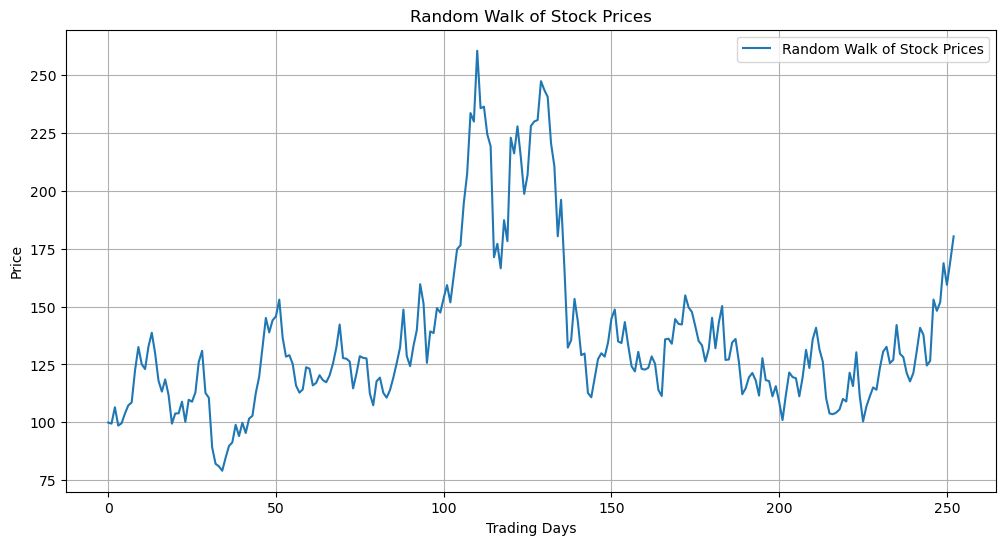

In [130]:
# Plot a single 'random walk' of stock prices
plt.figure(figsize=(12, 6))
plt.plot(price_series, label='Random Walk of Stock Prices')
plt.xlabel('Trading Days')
plt.ylabel('Price')
plt.title('Random Walk of Stock Prices')
plt.legend()
plt.grid(True)
plt.show()

# Now that we've created a single random walk above,
# we can simulate this process over a large sample size to
# get a better sense of the true expected distribution
number_of_trials = 3000

# Set up an additional array to collect all possible
# closing prices on the last day of the window.
# We can use this for a histogram to get a clearer sense of possible outcomes
closing_prices = []


C:\Users\prana\AppData\Local\Temp\ipykernel_23668\2480647723.py:5: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  price_series = [stock_name[('Close', stock_ticker)][-1]]


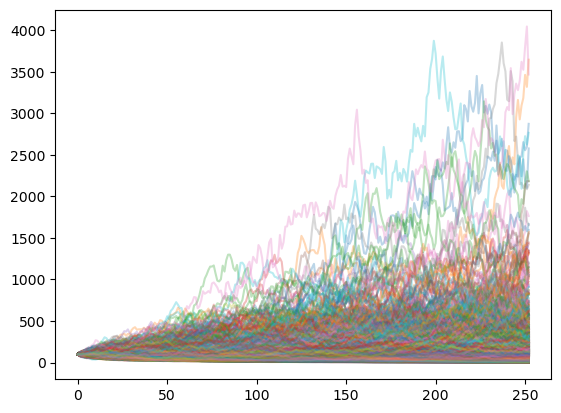

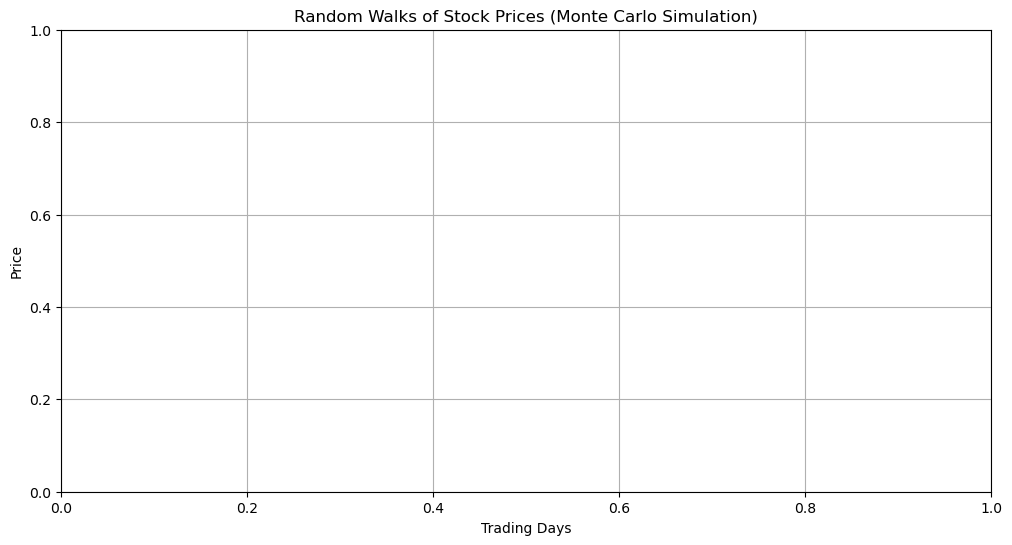

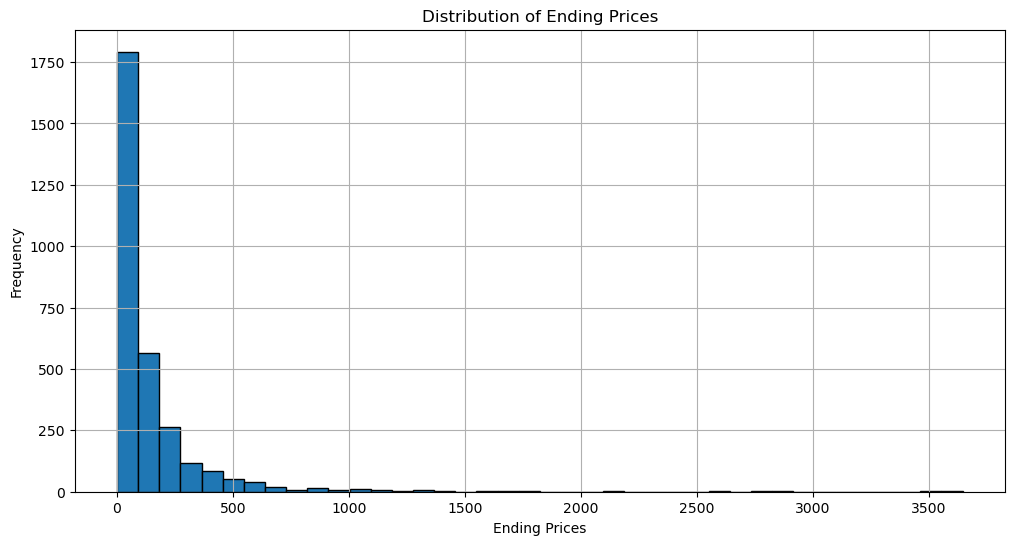

Expected price:  140.95


C:\Users\prana\AppData\Local\Temp\ipykernel_23668\2480647723.py:50: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.axvline(stock_name[('Close', stock_ticker)][-1], color='g', linestyle='dashed', linewidth=2, label='Current Price')


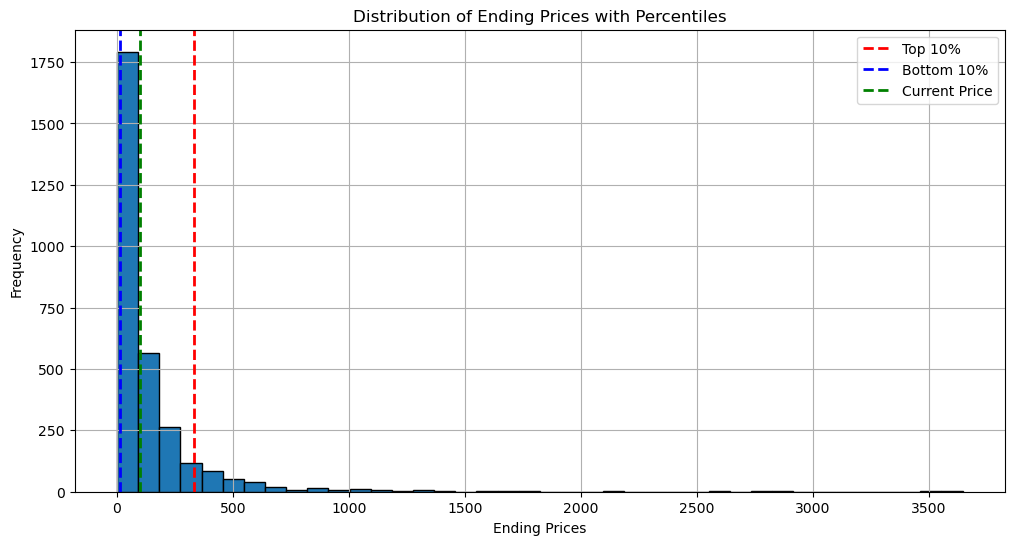

In [131]:
for i in range(number_of_trials):
    # Calculate randomized return percentages following our normal distribution
    # and using the mean / std dev we calculated above
    daily_return_percentages = np.random.normal(cagr / number_of_trading_days, std_dev / math.sqrt(number_of_trading_days), number_of_trading_days) + 1
    price_series = [stock_name[('Close', stock_ticker)][-1]]

    for j in daily_return_percentages:
        # Extrapolate the price out for the next year
        price_series.append(price_series[-1] * j)

    # Append closing prices on the last day of the window for the histogram
    closing_prices.append(price_series[-1])

    # Plot all random walks
    plt.plot(price_series, alpha=0.3)

plt.figure(figsize=(12, 6))
plt.xlabel('Trading Days')
plt.ylabel('Price')
plt.title('Random Walks of Stock Prices (Monte Carlo Simulation)')
plt.grid(True)
plt.show()

# Plot histogram
plt.figure(figsize=(12, 6))
plt.hist(closing_prices, bins=40, edgecolor='black')
plt.xlabel('Ending Prices')
plt.ylabel('Frequency')
plt.title('Distribution of Ending Prices')
plt.grid(True)
plt.show()

# Calculate the mean of all ending prices, allowing us to arrive at the most probable ending point
mean_end_price = round(np.mean(closing_prices), 2)
print("Expected price: ", str(mean_end_price))

# Lastly, split the distribution into percentiles to help gauge risk vs. reward

# Pull the top 10% of possible outcomes
top_ten = np.percentile(closing_prices, 100 - 10)

# Pull the bottom 10% of possible outcomes
bottom_ten = np.percentile(closing_prices, 10)

# Create the histogram again
plt.figure(figsize=(12, 6))
plt.hist(closing_prices, bins=40, edgecolor='black')
plt.axvline(top_ten, color='r', linestyle='dashed', linewidth=2, label='Top 10%')
plt.axvline(bottom_ten, color='b', linestyle='dashed', linewidth=2, label='Bottom 10%')
plt.axvline(stock_name[('Close', stock_ticker)][-1], color='g', linestyle='dashed', linewidth=2, label='Current Price')
plt.xlabel('Ending Prices')
plt.ylabel('Frequency')
plt.title('Distribution of Ending Prices with Percentiles')
plt.legend()
plt.grid(True)
plt.savefig('histogram.png')
plt.show()

In [132]:
# Store the data in a pickle file
data_to_pickle = {
    #'apple_data': apple,
    'closing_prices': closing_prices,
    'mean_end_price': mean_end_price,
    'top_ten_percentile': top_ten,
    'bottom_ten_percentile': bottom_ten,
}

pickle_file_path = 'stock_simulation_data_amd.pkl'

with open(pickle_file_path, 'wb') as pickle_file:
    pickle.dump(data_to_pickle, pickle_file)

print(f'Data has been saved to {pickle_file_path}')


Data has been saved to stock_simulation_data_amd.pkl


In [133]:
import pandas as pd
target_date = stock_name.index[-1] + pd.tseries.offsets.BDay(252)
print("Last data date:", stock_name.index[-1].date())
print("Expected price is for approx.:", target_date.date())
print("Expected price:", mean_end_price)

Last data date: 2026-10-09
Expected price is for approx.: 2027-09-28
Expected price: 140.95


# Enhanced Monte Carlo Simulation
## Incorporating Fundamentals, Analyst Price Targets & 1-Year Projection

The basic model above uses only historical drift (CAGR) and volatility.
Here we improve it by:
1. Pulling **company fundamentals** (P/E, EPS, earnings & revenue growth, beta)
2. Pulling **analyst price targets** (mean/median/high/low) — projections by market analysts
3. Pulling **EPS estimate trends** — forward earnings projections
4. **Blending** the historical CAGR with the analyst-implied 1-year return for the drift
5. Blending long-term volatility with **recent (2-year) volatility**
6. Producing a **1-year price projection** with percentile bands and probability of gain

In [134]:
# --- 1 & 2: Company fundamentals + analyst price targets ---
ticker = yf.Ticker(stock_ticker)
info = ticker.info

fundamentals = {
    'currentPrice': info.get('currentPrice'),
    'targetMeanPrice': info.get('targetMeanPrice'),
    'targetMedianPrice': info.get('targetMedianPrice'),
    'targetHighPrice': info.get('targetHighPrice'),
    'targetLowPrice': info.get('targetLowPrice'),
    'recommendationKey': info.get('recommendationKey'),
    'numberOfAnalystOpinions': info.get('numberOfAnalystOpinions'),
    'trailingPE': info.get('trailingPE'),
    'forwardPE': info.get('forwardPE'),
    'trailingEps': info.get('trailingEps'),
    'forwardEps': info.get('forwardEps'),
    'earningsGrowth': info.get('earningsGrowth'),
    'revenueGrowth': info.get('revenueGrowth'),
    'beta': info.get('beta'),
    'marketCap': info.get('marketCap'),
}

print(f"=== Fundamentals & Analyst Projections ({stock_ticker}) ===")
for k, v in fundamentals.items():
    print(f"{k}: {v}")

=== Fundamentals & Analyst Projections (KOD) ===
currentPrice: 99.87
targetMeanPrice: 116.66667
targetMedianPrice: 116.0
targetHighPrice: 145.0
targetLowPrice: 96.0
recommendationKey: strong_buy
numberOfAnalystOpinions: 6
trailingPE: None
forwardPE: -29.069498
trailingEps: -4.19
forwardEps: -3.43556
earningsGrowth: None
revenueGrowth: None
beta: 2.035
marketCap: 6276775424


In [135]:
# --- 3: Forward EPS estimate trends (analyst earnings projections) ---
try:
    eps_trend = ticker.eps_trend
    display(eps_trend)
except Exception as e:
    print("EPS trend unavailable:", e)

try:
    growth_estimates = ticker.growth_estimates
    display(growth_estimates)
except Exception as e:
    print("Growth estimates unavailable:", e)

,current,7daysAgo,30daysAgo,60daysAgo,90daysAgo,currency
period,,,,,,
0q,-1.01066,-1.01307,-1.01307,-0.92172,-0.93143,USD
+1q,-0.98431,-0.98799,-0.98799,-0.90111,-0.91592,USD
0y,-3.98086,-3.98721,-3.98721,-3.71414,-3.74179,USD
+1y,-3.43556,-3.74526,-3.74526,-3.10423,-3.11739,USD


,stockTrend,indexTrend
period,,
0q,0.1287,0.2438
+1q,0.0535,0.2602
0y,0.0785,0.3232
+1y,0.1370,0.1640
LTG,NaN,0.1220


In [136]:
# --- 4 & 5: Blended drift + blended volatility ---
current_price = float(stock_name[('Close', stock_ticker)].iloc[-1])

# Analyst-implied 1-year return (from mean price target)
analyst_mean_1y = fundamentals['targetMeanPrice']
if analyst_mean_1y:
    analyst_implied_return = (analyst_mean_1y / current_price) - 1
else:
    analyst_implied_return = None

# Blend: 50% historical CAGR + 50% analyst-implied return
if analyst_implied_return is not None:
    blended_drift = 0.5 * cagr + 0.5 * analyst_implied_return
else:
    blended_drift = cagr

# Volatility: blend full-history with recent 2-year volatility
close_series = stock_name[('Close', stock_ticker)]
recent = close_series.last('2Y') if hasattr(close_series, 'last') else close_series
std_dev_recent = recent.pct_change().std() * math.sqrt(252)
std_dev_blended = 0.5 * std_dev + 0.5 * std_dev_recent

print(f"Historical CAGR:            {cagr:.2%}")
print(f"Analyst-implied 1y return:  {analyst_implied_return:.2%}" if analyst_implied_return is not None else "Analyst-implied 1y return:  N/A")
print(f"Blended drift:              {blended_drift:.2%}")
print(f"Long-term volatility:       {std_dev:.2%}")
print(f"Recent 2y volatility:       {std_dev_recent:.2%}")
print(f"Blended volatility:         {std_dev_blended:.2%}")

Historical CAGR:            32.98%
Analyst-implied 1y return:  16.82%
Blended drift:              24.90%
Long-term volatility:       120.32%
Recent 2y volatility:       178.88%
Blended volatility:         149.60%


C:\Users\prana\AppData\Local\Temp\ipykernel_23668\2387332598.py:19: FutureWarning: last is deprecated and will be removed in a future version. Please create a mask and filter using `.loc` instead
  recent = close_series.last('2Y') if hasattr(close_series, 'last') else close_series
C:\Users\prana\AppData\Local\Temp\ipykernel_23668\2387332598.py:19: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  recent = close_series.last('2Y') if hasattr(close_series, 'last') else close_series


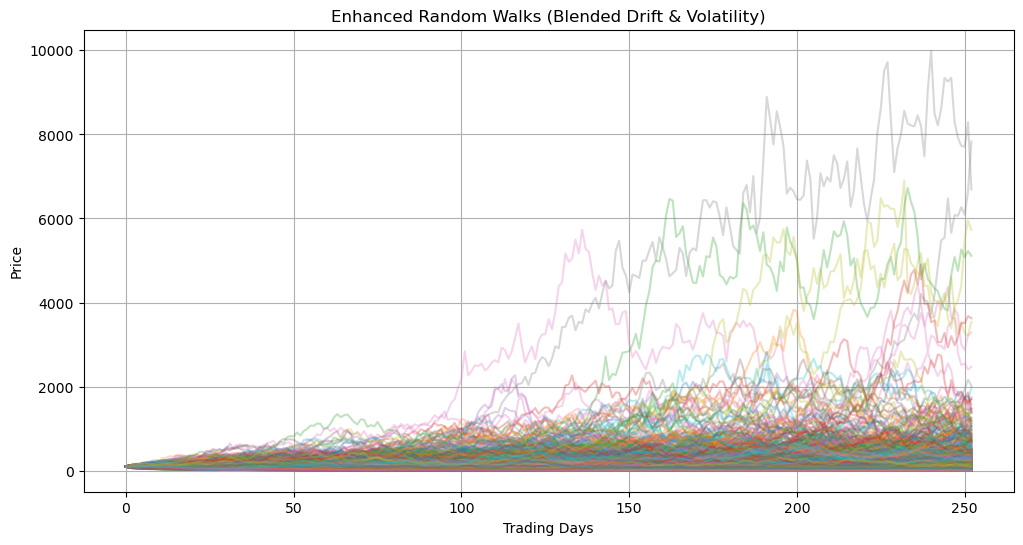

In [137]:
# --- 6: Enhanced simulation using blended drift & volatility ---
number_of_trials = 3000
enhanced_closing_prices = []

plt.figure(figsize=(12, 6))
for i in range(number_of_trials):
    daily_returns = np.random.normal(
        blended_drift / number_of_trading_days,
        std_dev_blended / math.sqrt(number_of_trading_days),
        number_of_trading_days
    ) + 1
    series = [current_price]
    for r in daily_returns:
        series.append(series[-1] * r)
    enhanced_closing_prices.append(series[-1])
    plt.plot(series, alpha=0.3)

plt.xlabel('Trading Days')
plt.ylabel('Price')
plt.title('Enhanced Random Walks (Blended Drift & Volatility)')
plt.grid(True)
plt.show()

In [138]:
# --- 1-YEAR PRICE PROJECTION (summary) ---
projection_date = stock_name.index[-1] + pd.tseries.offsets.BDay(252)

p5  = np.percentile(enhanced_closing_prices, 5)
p25 = np.percentile(enhanced_closing_prices, 25)
p50 = np.percentile(enhanced_closing_prices, 50)
p75 = np.percentile(enhanced_closing_prices, 75)
p95 = np.percentile(enhanced_closing_prices, 95)
enhanced_mean = round(np.mean(enhanced_closing_prices), 2)
prob_gain = np.mean([p > current_price for p in enhanced_closing_prices])

print("=" * 55)
print(f"1-YEAR PRICE PROJECTION FOR {stock_ticker}  ({projection_date.date()})")
print("=" * 55)
print(f"Current price:                 ${current_price:,.2f}")
print(f"Expected (mean) price:         ${enhanced_mean:,.2f}")
print(f"Median (50th percentile):      ${p50:,.2f}")
print(f"25th–75th percentile range:    ${p25:,.2f} – ${p75:,.2f}")
print(f"5th–95th percentile range:     ${p5:,.2f} – ${p95:,.2f}")
print(f"Probability of gain in 1 year: {prob_gain:.1%}")
if analyst_mean_1y:
    print(f"Analyst mean 1y target:        ${analyst_mean_1y:,.2f}")
print("=" * 55)

1-YEAR PRICE PROJECTION FOR KOD  (2027-09-28)
Current price:                 $99.87
Expected (mean) price:         $120.16
Median (50th percentile):      $39.97
25th–75th percentile range:    $15.22 – $111.09
5th–95th percentile range:     $3.66 – $454.49
Probability of gain in 1 year: 27.3%
Analyst mean 1y target:        $116.67


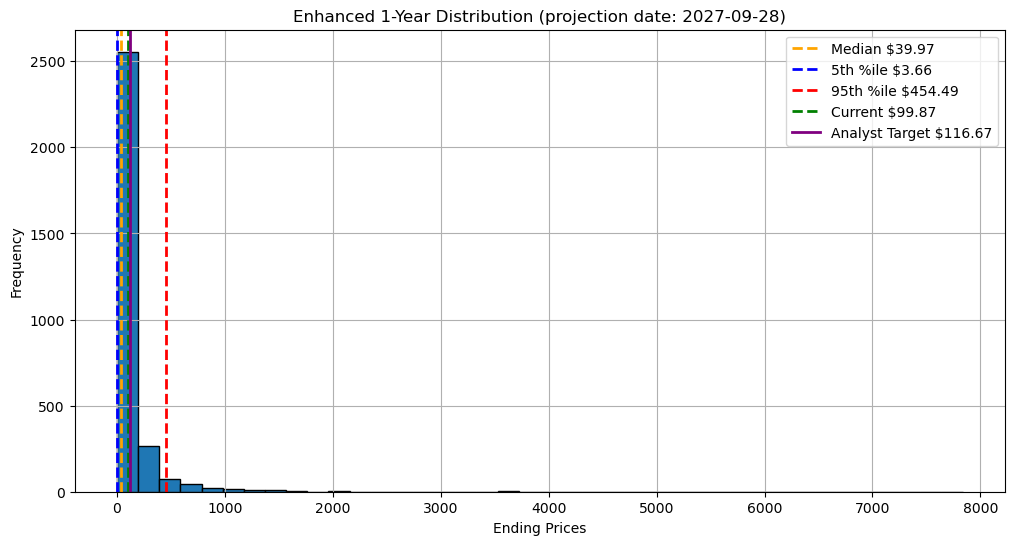

Saved to stock_simulation_data_KOD_enhanced.pkl


In [139]:
# --- Histogram of enhanced distribution with analyst targets overlay ---
plt.figure(figsize=(12, 6))
plt.hist(enhanced_closing_prices, bins=40, edgecolor='black')
plt.axvline(p50, color='orange', linestyle='dashed', linewidth=2, label=f'Median ${p50:,.2f}')
plt.axvline(p5, color='b', linestyle='dashed', linewidth=2, label=f'5th %ile ${p5:,.2f}')
plt.axvline(p95, color='r', linestyle='dashed', linewidth=2, label=f'95th %ile ${p95:,.2f}')
plt.axvline(current_price, color='g', linestyle='dashed', linewidth=2, label=f'Current ${current_price:,.2f}')
if analyst_mean_1y:
    plt.axvline(analyst_mean_1y, color='purple', linestyle='solid', linewidth=2, label=f'Analyst Target ${analyst_mean_1y:,.2f}')
plt.xlabel('Ending Prices')
plt.ylabel('Frequency')
plt.title(f'Enhanced 1-Year Distribution (projection date: {projection_date.date()})')
plt.legend()
plt.grid(True)
plt.savefig('histogram_enhanced.png')
plt.show()

# Save enhanced results
enhanced_data = {
    'enhanced_closing_prices': enhanced_closing_prices,
    'enhanced_mean': enhanced_mean,
    'p5': p5, 'p25': p25, 'p50': p50, 'p75': p75, 'p95': p95,
    'prob_gain': prob_gain,
    'projection_date': projection_date,
    'fundamentals': fundamentals,
    'blended_drift': blended_drift,
    'blended_volatility': std_dev_blended,
}
with open(f'stock_simulation_data_{stock_ticker}_enhanced.pkl', 'wb') as f:
    pickle.dump(enhanced_data, f)
print(f"Saved to stock_simulation_data_{stock_ticker}_enhanced.pkl")

In [140]:
print(f"Stock: {stock_ticker}")
proj_pct = (enhanced_mean / current_price - 1) * 100
print(f"Calculated 1-year projected price ({projection_date.date()}): ${enhanced_mean:,.2f} ({proj_pct:+.2f}%)")
if analyst_mean_1y:
    analyst_pct = (analyst_mean_1y / current_price - 1) * 100
    print(f"Analyst 1-year target price: ${analyst_mean_1y:,.2f} ({analyst_pct:+.2f}%)")
else:
    print("Analyst 1-year target price: N/A")

Stock: KOD
Calculated 1-year projected price (2027-09-28): $120.16 (+20.32%)
Analyst 1-year target price: $116.67 (+16.82%)
